In [71]:
import os
import copy
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [72]:

def prepare_train_test(
    file_path,
    x_col=0,
    y_col=1,
    has_header=None,
    test_size=0.2,
    random_state=42,
    scale_x=True,
):
    if not os.path.exists(file_path):
        raise FileNotFoundError(
             f"The file does not exist at the path: '{file_path}' Check the path, or place the file in the same folder as the notebook."
        )

    if has_header is None:
        ext = os.path.splitext(file_path)[1].lower()
        header_arg = 0 if ext == ".csv" else None
    else:
        header_arg = 0 if has_header else None

    df = pd.read_csv(file_path, header=header_arg)

    x_series = df[x_col] if isinstance(x_col, str) else df.iloc[:, x_col]
    y_series = df[y_col] if isinstance(y_col, str) else df.iloc[:, y_col]

    clean_df = pd.DataFrame({
        "x": pd.to_numeric(x_series, errors="coerce"),
        "y": pd.to_numeric(y_series, errors="coerce"),
    }).dropna()

    x_all = clean_df["x"].to_numpy(dtype=float)
    y_all = clean_df["y"].to_numpy(dtype=float)

    m_total = len(x_all)
    if m_total < 2:
        raise ValueError("عدد العينات الصالحة غير كافٍ للتقسيم إلى تدريب واختبار.")

    rng = np.random.default_rng(random_state)
    indices = rng.permutation(m_total)

    test_count = max(1, int(round(m_total * test_size)))
    test_count = min(test_count, m_total - 1)

    test_idx = indices[:test_count]
    train_idx = indices[test_count:]

    x_train_raw = x_all[train_idx]
    y_train = y_all[train_idx]
    x_test_raw = x_all[test_idx]
    y_test = y_all[test_idx]

    if scale_x:
        x_mean = float(np.mean(x_train_raw))
        x_std = float(np.std(x_train_raw))
        x_std_safe = x_std if x_std != 0 else 1.0
        x_train = (x_train_raw - x_mean) / x_std_safe
        x_test = (x_test_raw - x_mean) / x_std_safe
    else:
        x_mean = 0.0
        x_std_safe = 1.0
        x_train = x_train_raw.copy()
        x_test = x_test_raw.copy()

    return {
        "x_train": x_train,
        "y_train": y_train,
        "x_test": x_test,
        "y_test": y_test,
        "x_train_raw": x_train_raw,
        "x_test_raw": x_test_raw,
        "x_mean": x_mean,
        "x_std": x_std_safe,
    }


# --- تشغيل الجزء الأول وطباعة نتائجه مباشرة ---
file_path = "data1.txt"  # غيّر إلى اسم/مسار ملفك
x_col = 0                  # أو اسم العمود مثل "Population"
y_col = 1                  # أو اسم العمود مثل "Profit"
has_header = False         # اجعلها True إذا كان الملف يحتوي على صف عناوين

data = prepare_train_test(
    file_path=file_path,
    x_col=x_col,
    y_col=y_col,
    has_header=has_header,
    test_size=0.2,
    random_state=42,
    scale_x=True,
)

x_train, y_train = data["x_train"], data["y_train"]
x_test, y_test = data["x_test"], data["y_test"]

print("Data has been successfully loaded and partitioned:")
print(f"(Train): {len(x_train)}")
print(f"(Test) : {len(x_test)}")
print(f"First five elements of x_train (scaled): {np.round(x_train[:5], 4)}")
print(f"First five elements of y_train: {y_train[:5]}")

Data has been successfully loaded and partitioned:
(Train): 94
(Test) : 24
First five elements of x_train (scaled): [-0.1851  0.4952 -0.4459  0.0099 -0.483 ]
First five elements of y_train: [21.854   15.505    0.71618  7.5435   1.9869 ]


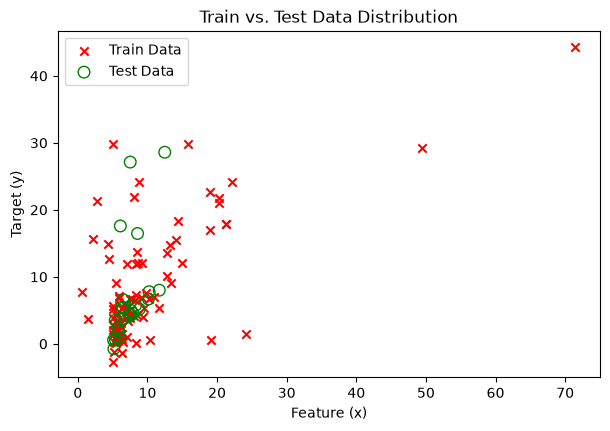

In [73]:
plt.figure(figsize=(7, 4.5))
plt.scatter(data["x_train_raw"], y_train, marker="x", c="r", label="Train Data")
plt.scatter(data["x_test_raw"], y_test, marker="o", facecolors="none", edgecolors="g", s=70, label="Test Data")
plt.title("Train vs. Test Data Distribution")
plt.xlabel(x_col if isinstance(x_col, str) else "Feature (x)")
plt.ylabel(y_col if isinstance(y_col, str) else "Target (y)")
plt.legend()
plt.show()

In [74]:
def compute_cost(x, y, w, b):
    m = x.shape[0]
    total_cost = 0.0
    for i in range(m):
        f_wb = w * x[i] + b
        total_cost += (f_wb - y[i]) ** 2
    return total_cost / (2 * m)


# --- تشغيل واختبار دالة التكلفة فوراً ---
initial_cost = compute_cost(x_train, y_train, w=0.0, b=0.0)
print(f"Initial cost at w=0, b=0: {initial_cost:.4f}")

Initial cost at w=0, b=0: 68.8032


In [75]:
def compute_gradient(x, y, w, b):
    m = x.shape[0]
    dj_dw = 0.0
    dj_db = 0.0
    for i in range(m):
        f_wb = w * x[i] + b
        dj_dw += (f_wb - y[i]) * x[i]
        dj_db += (f_wb - y[i])
    return dj_dw / m, dj_db / m


def gradient_descent(x, y, w_in, b_in, cost_function, gradient_function, alpha, num_iters):
    w = copy.deepcopy(w_in)
    b = b_in
    J_history = []
    w_history = []

    for i in range(num_iters):
        dj_dw, dj_db = gradient_function(x, y, w, b)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        if i < 100000:
            J_history.append(cost_function(x, y, w, b))

        if i % math.ceil(num_iters / 10) == 0:
            w_history.append(w)
            print(f"Iteration {i:4}: Cost {float(J_history[-1]):8.2f}")

    return w, b, J_history, w_history


# --- تشغيل التدريب الآن ---
w, b, J_history, _ = gradient_descent(
    x_train,
    y_train,
    w_in=0.0,
    b_in=0.0,
    cost_function=compute_cost,
    gradient_function=compute_gradient,
    alpha=0.01,
    num_iters=1500,
)
print(f"\nResult after training -> w = {w:.4f}, b = {b:.4f}")

Iteration    0: Cost    67.84
Iteration  150: Cost    22.73
Iteration  300: Cost    20.51
Iteration  450: Cost    20.41
Iteration  600: Cost    20.40
Iteration  750: Cost    20.40
Iteration  900: Cost    20.40
Iteration 1050: Cost    20.40
Iteration 1200: Cost    20.40
Iteration 1350: Cost    20.40

Result after training -> w = 5.5679, b = 8.1121


In [76]:
def evaluate_model(x, y, w, b):
    x_arr = np.asarray(x, dtype=float)
    y_arr = np.asarray(y, dtype=float)
    y_pred = w * x_arr + b

    errors = y_pred - y_arr
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))

    ss_res = float(np.sum((y_arr - y_pred) ** 2))
    ss_tot = float(np.sum((y_arr - np.mean(y_arr)) ** 2))
    r2 = float(1.0 - (ss_res / ss_tot)) if ss_tot != 0 else 0.0

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "y_pred": y_pred,
    }


# --- تشغيل التقييم وطباعته الآن ---
train_metrics = evaluate_model(x_train, y_train, w, b)
test_metrics = evaluate_model(x_test, y_test, w, b)

print("===Training Results (Train) ===")
print(f"MAE  : {train_metrics['MAE']:.4f}")
print(f"RMSE : {train_metrics['RMSE']:.4f}")
print(f"R^2  : {train_metrics['R2']:.4f}")

print("\n=== Test results (Test) ===")
print(f"MAE  : {test_metrics['MAE']:.4f}")
print(f"RMSE : {test_metrics['RMSE']:.4f}")
print(f"R^2  : {test_metrics['R2']:.4f}")

===Training Results (Train) ===
MAE  : 4.6464
RMSE : 6.3874
R^2  : 0.4318

=== Test results (Test) ===
MAE  : 4.6319
RMSE : 6.9687
R^2  : 0.1440


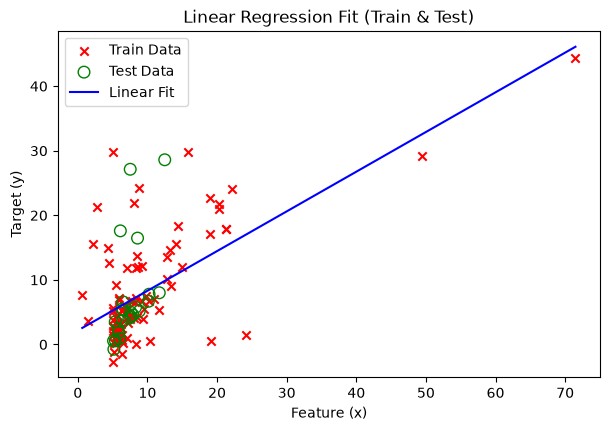

For input = 3.5 -> Predicted y = 4.31
For input = 7.0 -> Predicted y = 6.46


In [77]:
order = np.argsort(data["x_train_raw"])
x_sorted_raw = data["x_train_raw"][order]
y_sorted_pred = (w * x_train[order]) + b

plt.figure(figsize=(7, 4.5))
plt.scatter(data["x_train_raw"], y_train, marker="x", c="r", label="Train Data")
plt.scatter(data["x_test_raw"], y_test, marker="o", facecolors="none", edgecolors="g", s=70, label="Test Data")
plt.plot(x_sorted_raw, y_sorted_pred, c="b", label="Linear Fit")
plt.title("Linear Regression Fit (Train & Test)")
plt.xlabel(x_col if isinstance(x_col, str) else "Feature (x)")
plt.ylabel(y_col if isinstance(y_col, str) else "Target (y)")
plt.legend()
plt.show()


def predict_new(x_new_value, w, b, x_mean, x_std):
    x_scaled = (x_new_value - x_mean) / x_std
    return w * x_scaled + b


# --- تشغيل التنبؤ على قيم جديدة الآن ---
for sample_x in [3.5, 7.0]:
    pred_y = predict_new(sample_x, w, b, data["x_mean"], data["x_std"])
    print(f"For input = {sample_x} -> Predicted y = {pred_y:.2f}")